# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+png'   # interactive in Jupyter/VS Code + static image so GitHub shows the charts

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Line chart, indexed to 1970 (1970 = 1×).** The question is about growth over time *relative to each continent's own 1970 size*, so I divided every continent's population by its 1970 value: the lines show the trajectories, and continents of very different sizes become directly comparable (raw totals would let Asia dwarf everything).

*Design:* Africa, the answer, is the only coloured line (colour-blind-safe blue); the other continents are grey context. Each line is labelled at its end with its growth multiple instead of a legend, the subtitle carries the unit so no axis titles are needed, and only faint horizontal gridlines are kept for reading off the multiples.

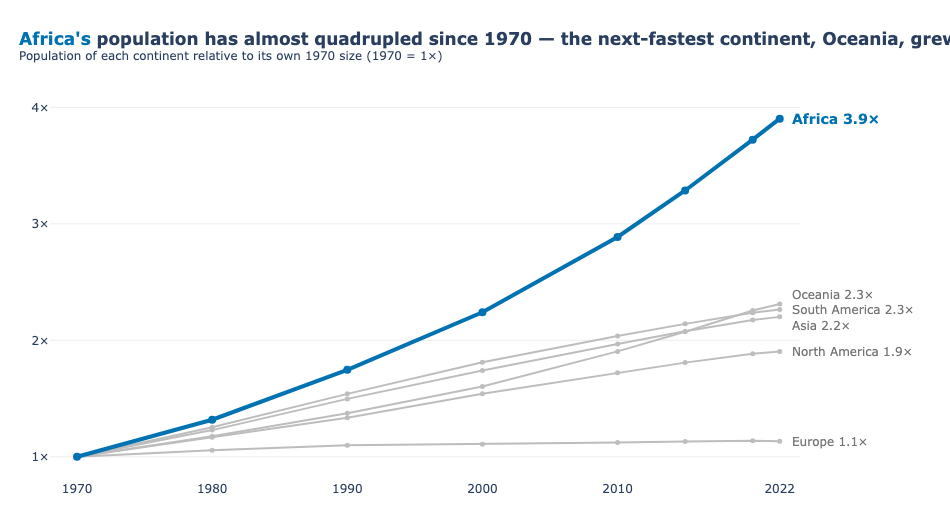

In [2]:
# Q1
GREY, ACCENT = '#BDBDBD', '#0072B2'          # grey = context, blue = the answer (CVD-safe)

# Total population per continent and year, then divide by each continent's own 1970 value (1970 = 1×)
q1 = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base_1970 = q1[q1['Year'] == 1970].set_index('Continent')['Population']
q1['Growth'] = q1['Population'] / q1['Continent'].map(base_1970)

end = q1[q1['Year'] == 2022].set_index('Continent')['Growth'].sort_values()
runner_up = end.drop('Africa').idxmax()          # next-fastest continent, for the title

fig = px.line(q1, x='Year', y='Growth', color='Continent', markers=True,
              category_orders={'Continent': list(end.index)},          # Africa drawn last = on top
              color_discrete_map={c: ACCENT if c == 'Africa' else GREY for c in end.index},
              template='plotly_white')

fig.update_traces(line=dict(width=2), marker=dict(size=5),
                  hovertemplate='<b>%{fullData.name}</b><br>%{x}: %{y:.2f}× its 1970 size<extra></extra>')
fig.update_traces(selector=dict(name='Africa'), line=dict(width=4), marker=dict(size=8))

# Direct labels at the end of each line instead of a legend (nudged apart where lines end close together)
nudge = {'Oceania': 9, 'South America': 0, 'Asia': -9}
for continent, value in end.items():
    is_africa = continent == 'Africa'
    fig.add_annotation(x=2022, y=value, text=f'<b>{continent} {value:.1f}×</b>' if is_africa else f'{continent} {value:.1f}×',
                       xanchor='left', xshift=10, yshift=nudge.get(continent, 0), showarrow=False,
                       font=dict(size=14 if is_africa else 12, color=ACCENT if is_africa else '#757575'))

fig.update_layout(
    title=dict(text=f"<b><span style='color:{ACCENT}'>Africa's</span> population has almost quadrupled since 1970 — "
                    f"the next-fastest continent, {runner_up}, grew {end[runner_up]:.1f}×</b>"
                    "<br><sup>Population of each continent relative to its own 1970 size (1970 = 1×)</sup>",
               x=0.02, xanchor='left'),
    showlegend=False, width=950, height=520, margin=dict(l=50, r=150, t=90, b=40))
fig.update_xaxes(title=None, showgrid=False, tickvals=[1970, 1980, 1990, 2000, 2010, 2022], range=[1968, 2023.5])
fig.update_yaxes(title=None, tickvals=[1, 2, 3, 4], ticktext=['1×', '2×', '3×', '4×'],
                 gridcolor='#EEEEEE', zeroline=False, range=[0.8, 4.15])
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Sorted horizontal bar chart.** Ranking 15 named countries by one quantity is a job for bars sorted from largest to smallest, and horizontal bars keep the country names readable.

*Design:* Colour answers the second half of the question: African countries are blue, all others grey, and "Africa" is coloured in the title so no legend is needed. Every bar carries its value, so the x-axis and gridlines are removed; the subtitle adds that India and China alone account for about a third of all growth.

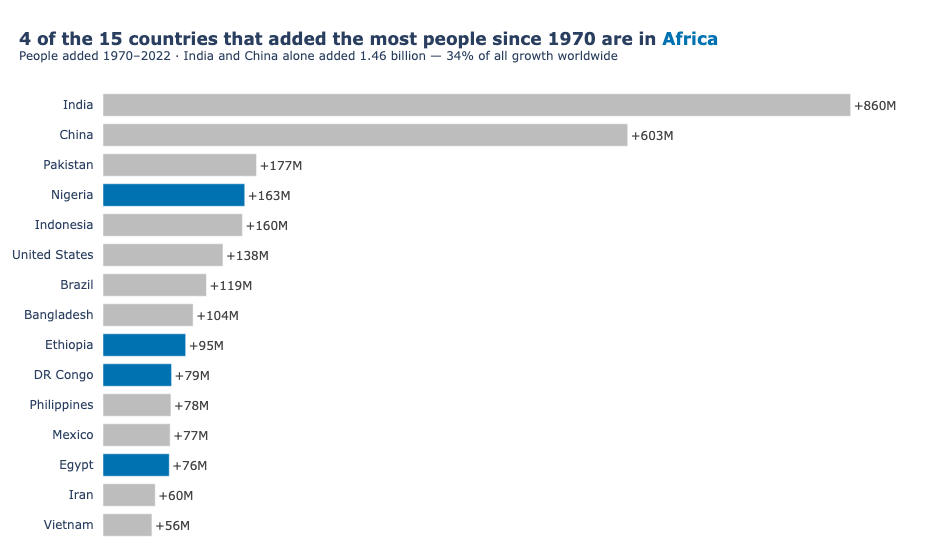

In [3]:
# Q2
GREY, ACCENT = '#BDBDBD', '#0072B2'

q2 = df.assign(Added=df['2022 Population'] - df['1970 Population'])
world_added = q2['Added'].sum()
q2 = q2.nlargest(15, 'Added')
q2['Group'] = np.where(q2['Continent'] == 'Africa', 'Africa', 'Rest of the world')
q2['Label'] = (q2['Added'] / 1e6).map('+{:,.0f}M'.format)

n_africa = (q2['Group'] == 'Africa').sum()
top2 = q2.nlargest(2, 'Added')                                   # India and China

fig = px.bar(q2, x='Added', y='Country', orientation='h', color='Group', text='Label',
             color_discrete_map={'Africa': ACCENT, 'Rest of the world': GREY},
             hover_data={'Continent': True, 'Added': ':,', 'Group': False, 'Label': False},
             template='plotly_white')

fig.update_traces(textposition='outside', cliponaxis=False, textfont=dict(size=12, color='#444444'))
fig.update_yaxes(title=None, categoryorder='total ascending', ticksuffix='  ')   # biggest at the top
fig.update_xaxes(visible=False)                                          # values are on the bars
fig.update_layout(
    title=dict(text=f"<b>{n_africa} of the 15 countries that added the most people since 1970 are in "
                    f"<span style='color:{ACCENT}'>Africa</span></b>"
                    f"<br><sup>People added 1970–2022 · {top2['Country'].iloc[0]} and {top2['Country'].iloc[1]} alone added "
                    f"{top2['Added'].sum() / 1e9:.2f} billion — {top2['Added'].sum() / world_added:.0%} of all growth worldwide</sup>",
               x=0.02, xanchor='left'),
    showlegend=False, bargap=0.25, width=950, height=560, margin=dict(l=20, r=60, t=90, b=20))
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Scatter plot on log–log axes, shown as small multiples (one panel per continent).** Area vs population is a relationship between two numeric variables, and both span six or more orders of magnitude, so log scales are needed to see anything besides the giants.

*Design:* Each panel shows every country in grey for context and highlights one continent in blue against the same dashed world trend line, so the continents can be compared without a six-colour legend. Panels are ordered from furthest above the trend (Asia) to furthest below (Oceania), and each panel title states how far its typical country sits from the trend. The countries that break the pattern most (the furthest above and below the trend in each continent, if more than 10× off it) are labelled directly.

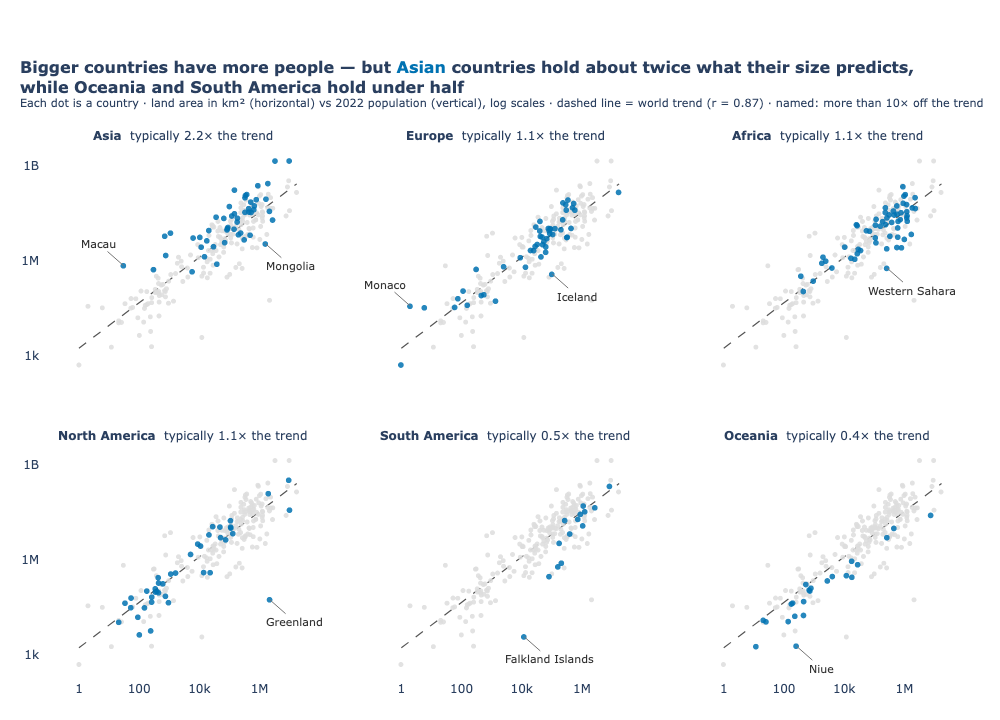

In [4]:
# Q3
GREY, ACCENT = '#DDDDDD', '#0072B2'

# World trend on log–log scales: log10(population) = b0 + b1 · log10(area)
log_area, log_pop = np.log10(df['Area']), np.log10(df['2022 Population'])
b1, b0 = np.polyfit(log_area, log_pop, 1)
r = np.corrcoef(log_area, log_pop)[0, 1]
q3 = df.assign(Residual=log_pop - (b0 + b1 * log_area))     # > 0: more people than the trend predicts

# How far each continent's typical country sits from the trend (10**median residual = "× the trend")
vs_trend = 10 ** q3.groupby('Continent')['Residual'].median().sort_values(ascending=False)

# Small multiples: every panel shows ALL countries in grey for context and highlights one continent
panels = pd.concat([q3.assign(Panel=c) for c in vs_trend.index], ignore_index=True)
panels['Group'] = np.where(panels['Continent'] == panels['Panel'], 'Highlighted', 'Context')

fig = px.scatter(panels, x='Area', y='2022 Population', facet_col='Panel', facet_col_wrap=3,
                 color='Group', log_x=True, log_y=True, hover_name='Country',
                 hover_data={'Panel': False, 'Group': False, 'Area': ':,', '2022 Population': ':,'},
                 category_orders={'Panel': list(vs_trend.index), 'Group': ['Context', 'Highlighted']},
                 color_discrete_map={'Context': GREY, 'Highlighted': ACCENT},
                 facet_col_spacing=0.04, facet_row_spacing=0.12, template='plotly_white')
fig.update_traces(marker=dict(size=6, opacity=0.85))
fig.update_traces(selector=dict(name='Context'), hoverinfo='skip', hovertemplate=None, marker=dict(size=5))

# Facet titles: continent + how far its typical country sits from the world trend
fig.for_each_annotation(lambda a: a.update(
    text=f"<b>{a.text.split('=')[-1]}</b>  typically {vs_trend[a.text.split('=')[-1]]:.1f}× the trend"))

# Same dashed world trend line in every panel
xs = np.logspace(np.log10(df['Area'].min()), np.log10(df['Area'].max()), 50)
fig.add_scatter(x=xs, y=10 ** (b0 + b1 * np.log10(xs)), mode='lines', hoverinfo='skip', showlegend=False,
                line=dict(color='#555555', width=1.2, dash='dash'), row='all', col='all')

# Label the countries that break the pattern: the furthest above and below the trend in each continent,
# if they sit more than 10× off it (|residual| > 1 on the log scale)
breakers = pd.concat([q3.loc[q3.groupby('Continent')['Residual'].idxmax()],
                      q3.loc[q3.groupby('Continent')['Residual'].idxmin()]])
breakers = breakers[breakers['Residual'].abs() > 1].set_index('Country')
for trace in fig.data:
    if trace.name != 'Highlighted':
        continue
    for country, x, y in zip(trace.hovertext, trace.x, trace.y):
        if country in breakers.index:
            above = breakers.loc[country, 'Residual'] > 0
            fig.add_annotation(x=np.log10(x), y=np.log10(y), xref=trace.xaxis, yref=trace.yaxis, text=country,
                               showarrow=True, arrowhead=0, arrowwidth=1, arrowcolor='#757575',
                               ax=-25 if above else 25, ay=-22 if above else 22, font=dict(size=11, color='#333333'))

fig.update_xaxes(title=None, showgrid=False, tickvals=[1, 100, 1e4, 1e6], ticktext=['1', '100', '10k', '1M'])
fig.update_yaxes(title=None, showgrid=False, tickvals=[1e3, 1e6, 1e9], ticktext=['1k', '1M', '1B'])
fig.update_layout(
    title=dict(text=f"<b>Bigger countries have more people — but <span style='color:{ACCENT}'>Asian</span> countries hold "
                    f"about twice what their size predicts,<br>while Oceania and South America hold under half</b>"
                    f"<br><sup>Each dot is a country · land area in km² (horizontal) vs 2022 population (vertical), log scales · "
                    f"dashed line = world trend (r = {r:.2f}) · named: more than 10× off the trend</sup>",
               x=0.02, xanchor='left', font=dict(size=16)),
    showlegend=False, width=1000, height=720, margin=dict(l=40, r=30, t=145, b=40))
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Box plot with every country shown as a dot, on a log scale.** A box plot puts each continent's median, middle 50% and outliers side by side, which is exactly "the spread, not just the average". I chose it over a violin plot because some continents have few countries (South America has 14), where a smoothed density shape would suggest more than the data supports; the dots keep every country visible.

*Design:* Density runs from 0.03 to over 23,000 people per km², so the boxes are computed on log10(density) to match the log axis. Continents are sorted by median, the medians are written into the axis labels, the extremes are named, and South America is the accent because it is the only continent that is sparse throughout.

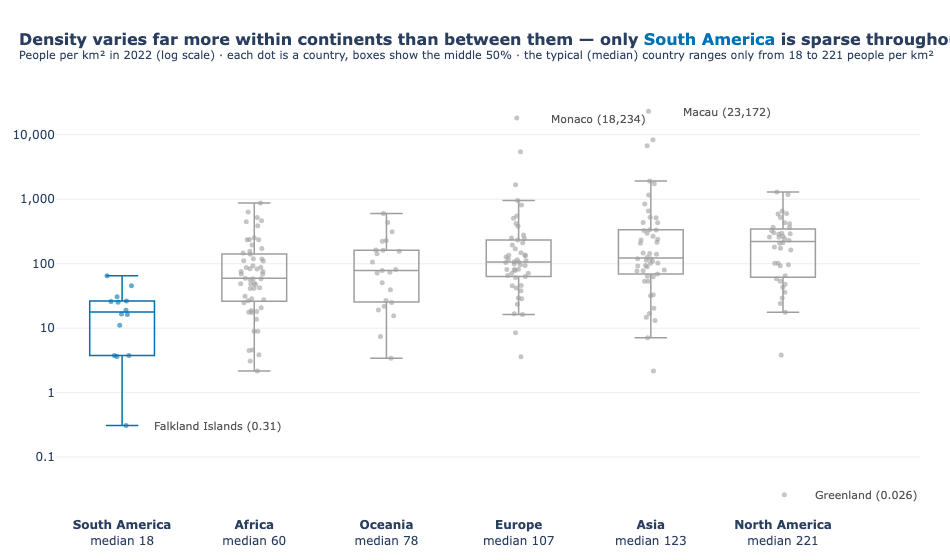

In [5]:
# Q4
GREY, ACCENT = '#9E9E9E', '#0072B2'

# Box statistics are computed on log10(density) so the boxes and whiskers match the log scale we read them on
q4 = df.assign(LogDensity=np.log10(df['Density']))
medians = q4.groupby('Continent')['Density'].median().sort_values()        # order continents by typical density
uniformly_sparse = q4.groupby('Continent')['Density'].max().idxmin()        # continent whose densest country is least dense

fig = px.box(q4, x='Continent', y='LogDensity', color='Continent', points='all',
             hover_name='Country', hover_data={'Continent': False, 'LogDensity': False, 'Density': ':,.1f'},
             category_orders={'Continent': list(medians.index)},
             color_discrete_map={c: ACCENT if c == uniformly_sparse else GREY for c in medians.index},
             template='plotly_white')
fig.update_traces(jitter=0.5, pointpos=0, marker=dict(size=5, opacity=0.6), line=dict(width=1.5),
                  fillcolor='rgba(0,0,0,0)')

# Name the extremes so the reader sees what the spread is made of
extremes = pd.concat([q4.nlargest(2, 'Density'), q4.nsmallest(2, 'Density')])
for _, row in extremes.iterrows():
    value = f"{row['Density']:.2g}" if row['Density'] < 1 else f"{row['Density']:,.0f}"
    fig.add_annotation(x=row['Continent'], y=row['LogDensity'], text=f"{row['Country']} ({value})",
                       showarrow=False, xanchor='left', xshift=30, font=dict(size=11, color='#555555'))

# Medians written into the axis labels (direct labels instead of a legend)
fig.update_xaxes(title=None, tickvals=list(medians.index),
                 ticktext=[f'<b>{c}</b><br>median {m:,.0f}' for c, m in medians.items()])
fig.update_yaxes(title=None, tickvals=[-1, 0, 1, 2, 3, 4],
                 ticktext=['0.1', '1', '10', '100', '1,000', '10,000'], gridcolor='#EEEEEE', zeroline=False)
fig.update_layout(
    title=dict(text=f"<b>Density varies far more within continents than between them — "
                    f"only <span style='color:{ACCENT}'>{uniformly_sparse}</span> is sparse throughout</b>"
                    f"<br><sup>People per km² in 2022 (log scale) · each dot is a country, boxes show the middle 50% · "
                    f"the typical (median) country ranges only from {medians.min():,.0f} to {medians.max():,.0f} people per km²</sup>",
               x=0.02, xanchor='left', font=dict(size=16)),
    showlegend=False, boxmode='overlay', width=950, height=560, margin=dict(l=50, r=30, t=90, b=40))
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Choropleth map.** The question asks *where in the world* populations grew or shrank, so the answer has to be geographic.

*Design:* The 2000–2022 percentage change is binned into a diverging orange–blue scheme (orange = shrank, blue = grew, darker = bigger change), which is colour-blind safe and makes the sign of the change readable at a glance; bins also stop the long right tail (Qatar +317%) from washing out the rest of the scale. The legend stays because the bins need a key; the frame, coastlines and Antarctica are removed to declutter.

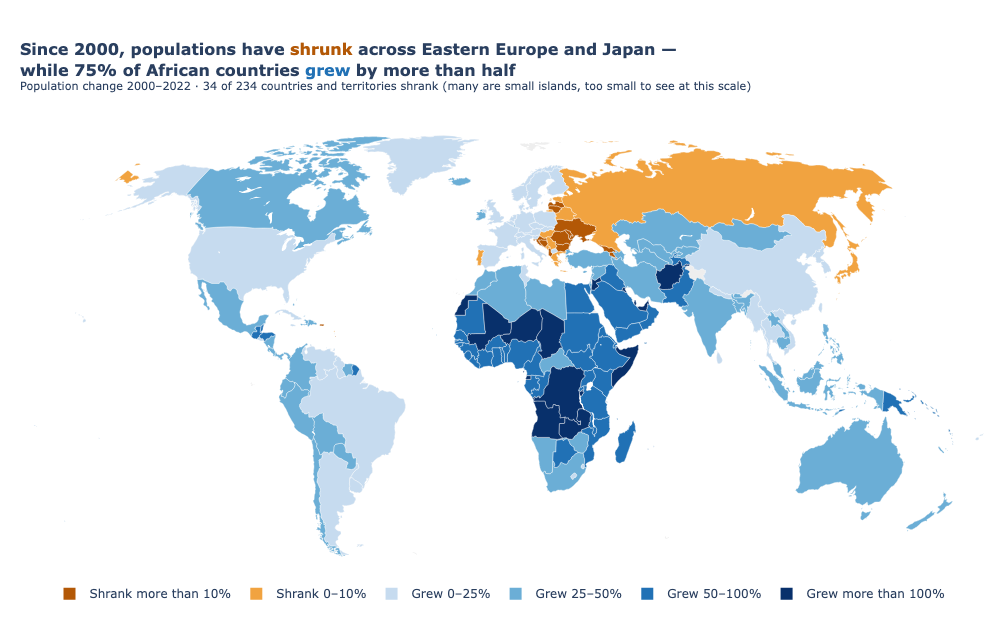

In [6]:
# Q5
q5 = df.assign(Change=(df['2022 Population'] / df['2000 Population'] - 1) * 100)

# Bin the % change: orange = shrank, blue = grew, darker = bigger change (diverging, colour-blind safe)
bands = ['Shrank more than 10%', 'Shrank 0–10%', 'Grew 0–25%', 'Grew 25–50%', 'Grew 50–100%', 'Grew more than 100%']
colors = ['#B35806', '#F1A340', '#C6DBEF', '#6BAED6', '#2171B5', '#08306B']
q5['Change band'] = pd.cut(q5['Change'], bins=[-np.inf, -10, 0, 25, 50, 100, np.inf], labels=bands, right=False).astype(str)

n_shrank = (q5['Change'] < 0).sum()
africa = q5[q5['Continent'] == 'Africa']
africa_over_half = (africa['Change'] > 50).mean()

fig = px.choropleth(q5, locations='CCA3', locationmode='ISO-3', color='Change band',
                    color_discrete_map=dict(zip(bands, colors)), category_orders={'Change band': bands},
                    hover_name='Country', hover_data={'Change': ':+.1f', 'CCA3': False, 'Change band': False},
                    labels={'Change': '% change 2000–2022'}, template='plotly_white')

fig.update_traces(marker_line_color='white', marker_line_width=0.4)
fig.update_geos(projection_type='natural earth', showframe=False, showcoastlines=False,
                showland=True, landcolor='#EEEEEE', lataxis_range=[-58, 85])           # hide Antarctica
fig.update_layout(
    title=dict(text="<b>Since 2000, populations have <span style='color:#B35806'>shrunk</span> across Eastern Europe and Japan —"
                    f"<br>while {africa_over_half:.0%} of African countries <span style='color:#2171B5'>grew</span> by more than half</b>"
                    f"<br><sup>Population change 2000–2022 · {n_shrank} of {len(q5)} countries and territories shrank "
                    "(many are small islands, too small to see at this scale)</sup>",
               x=0.02, xanchor='left', font=dict(size=16)),
    legend=dict(title=None, orientation='h', x=0.5, xanchor='center', y=-0.02, yanchor='top', font=dict(size=12)),
    width=1000, height=620, margin=dict(l=10, r=10, t=110, b=50))
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**Treemap.** This is a two-level part-to-whole question (continent → country), and a treemap shows both levels in one figure, with each box's area proportional to population.

*Design:* Asia gets the accent colour because it holds most of the world's people; the other continents are grey context. Continent headers carry their share of the world and each country tile its own share; labels that don't fit are hidden rather than shrunk to an unreadable size.

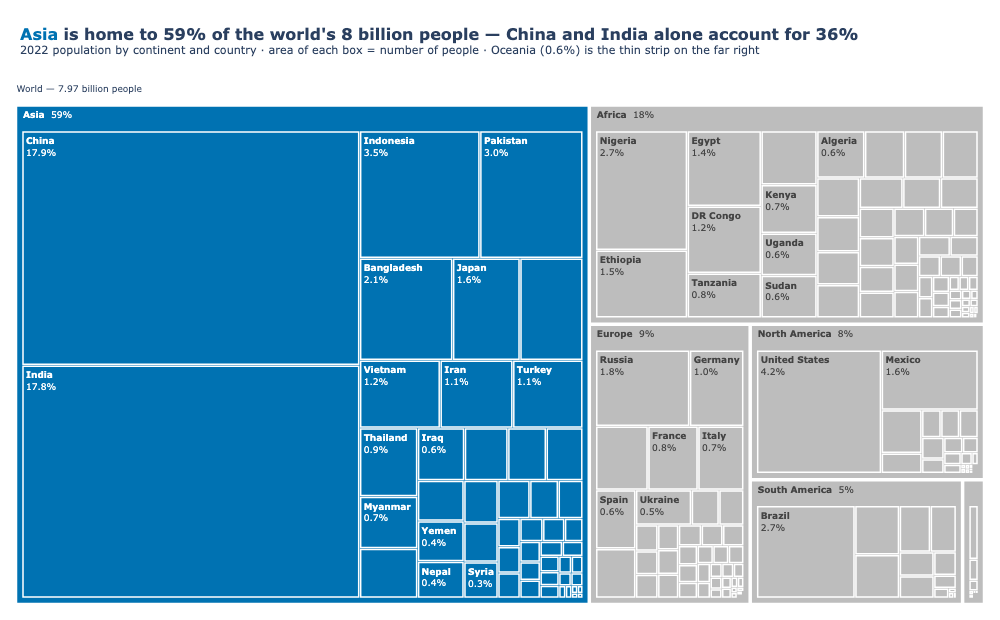

In [7]:
# Q6
GREY, ACCENT = '#BDBDBD', '#0072B2'

world = df['2022 Population'].sum()
asia_share = df.loc[df['Continent'] == 'Asia', '2022 Population'].sum() / world
top2 = df.nlargest(2, '2022 Population')                                  # China and India

# Treemap headers only show the label, so the continent's share goes into its label: 'Asia  59%'
continent_share = df.groupby('Continent')['2022 Population'].sum() / world
q6 = df.assign(Region=df['Continent'].map(lambda c: f'<b>{c}</b>  {continent_share[c]:.0%}' if continent_share[c] >= 0.01
                                          else f'<b>{c}</b>  {continent_share[c]:.1%}'))

fig = px.treemap(q6, path=[px.Constant(f'World — {world / 1e9:.2f} billion people'), 'Region', 'Country'],
                 values='2022 Population', color='Continent',
                 color_discrete_map={'(?)': '#FFFFFF', **{c: ACCENT if c == 'Asia' else GREY for c in df['Continent'].unique()}},
                 template='plotly_white')

fig.update_traces(texttemplate='<b>%{label}</b><br>%{percentRoot:.1%}', textfont=dict(size=13),
                  hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentRoot:.1%} of the world<extra></extra>',
                  marker=dict(line=dict(color='white', width=1.5)), root_color='white', tiling=dict(pad=2))
fig.update_layout(
    title=dict(text=f"<b><span style='color:{ACCENT}'>Asia</span> is home to {asia_share:.0%} of the world's "
                    f"{world / 1e9:.0f} billion people — {top2['Country'].iloc[0]} and {top2['Country'].iloc[1]} alone "
                    f"account for {top2['2022 Population'].sum() / world:.0%}</b>"
                    "<br><sup>2022 population by continent and country · area of each box = number of people · Oceania (0.6%) is the thin strip on the far right</sup>",
               x=0.02, xanchor='left', font=dict(size=16)),
    uniformtext=dict(minsize=9, mode='hide'),          # hide labels that don't fit instead of shrinking them
    width=1000, height=620, margin=dict(l=10, r=10, t=80, b=10))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

**100% stacked bar chart.** The question is about shares of a whole changing over time; 100% stacked bars hold the total fixed, so only the composition changes.

*Design:* The two stories sit on the two straight edges: Africa (rising, blue) on the bottom baseline and Europe (falling, orange) on top, so both are read against a flat edge, while Asia and the rest of the world are grey context. Every segment is labelled and the groups are named next to the last bar instead of a legend, so the y-axis is removed. The bars are the dataset's eight snapshot years, so the gaps after 2010 are shorter (5, 5 and 2 years).

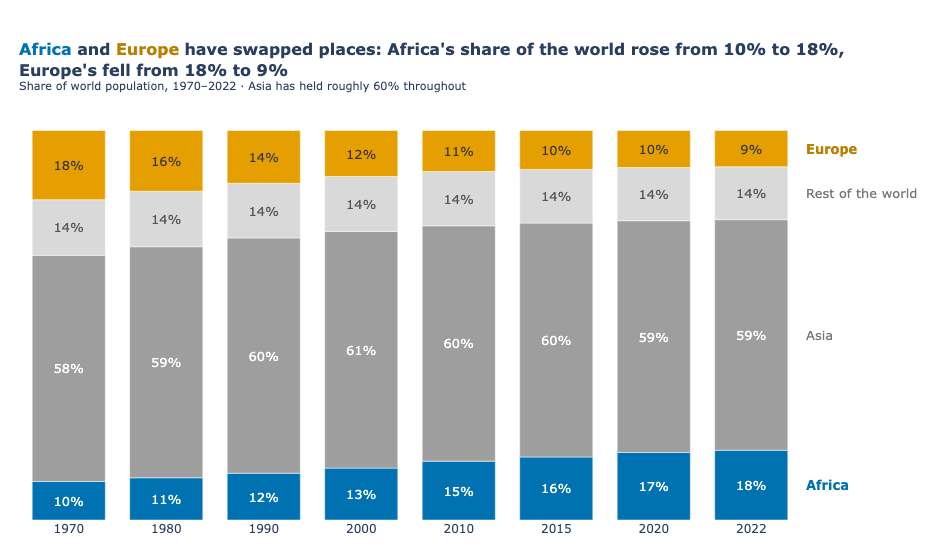

In [8]:
# Q7
BLUE, ORANGE, GREY, LIGHT_GREY = '#0072B2', '#E69F00', '#9E9E9E', '#D9D9D9'

q7 = df_long.assign(Group=np.where(df_long['Continent'].isin(['Africa', 'Asia', 'Europe']),
                                   df_long['Continent'], 'Rest of the world'))
q7 = q7.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
q7['Share'] = q7['Population'] / q7.groupby('Year')['Population'].transform('sum') * 100
q7['Year'] = q7['Year'].astype(str)                     # the 8 snapshot years as categories

share = q7.pivot(index='Year', columns='Group', values='Share')
stack = ['Africa', 'Asia', 'Rest of the world', 'Europe']    # bottom → top: the two stories sit on the two flat edges

fig = px.bar(q7, x='Year', y='Share', color='Group', category_orders={'Group': stack},
             color_discrete_map={'Africa': BLUE, 'Asia': GREY, 'Rest of the world': LIGHT_GREY, 'Europe': ORANGE},
             hover_data={'Share': ':.1f', 'Population': ':,'}, template='plotly_white')

fig.update_traces(texttemplate='%{y:.0f}%', textposition='inside', insidetextanchor='middle', textfont=dict(size=13))
fig.update_traces(selector=dict(name='Africa'), textfont_color='white')
fig.update_traces(selector=dict(name='Asia'), textfont_color='white')
fig.update_traces(selector=dict(name='Rest of the world'), textfont_color='#555555')
fig.update_traces(selector=dict(name='Europe'), textfont_color='#333333')

# Direct labels next to the last bar instead of a legend
last = share.loc['2022', stack]
for group, mid in zip(stack, last.cumsum() - last / 2):
    color = {'Africa': BLUE, 'Europe': '#B97F00'}.get(group, '#757575')
    fig.add_annotation(xref='paper', x=1, y=mid, text=f'<b>{group}</b>' if group in ('Africa', 'Europe') else group,
                       xanchor='left', xshift=4, showarrow=False, font=dict(size=13, color=color))

a0, a1 = share.loc['1970', 'Africa'], share.loc['2022', 'Africa']
e0, e1 = share.loc['1970', 'Europe'], share.loc['2022', 'Europe']
fig.update_xaxes(title=None, type='category')         # otherwise Plotly reads '1970' as a number
fig.update_yaxes(visible=False)
fig.update_layout(
    title=dict(text=f"<b><span style='color:{BLUE}'>Africa</span> and <span style='color:#B97F00'>Europe</span> have swapped places: "
                    f"Africa's share of the world rose from {a0:.0f}% to {a1:.0f}%,<br>Europe's fell from {e0:.0f}% to {e1:.0f}%</b>"
                    "<br><sup>Share of world population, 1970–2022 · Asia has held roughly 60% throughout</sup>",
               x=0.02, xanchor='left', font=dict(size=16)),
    showlegend=False, bargap=0.25, width=950, height=560, margin=dict(l=20, r=150, t=110, b=40))
fig.show()